In [1]:
# import library
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# load data
df = pd.read_csv('dataset.csv')

# lihat 10 baris pertama data
df.head()

,Nama Produk,Varian Warna,Hex Code,Harga,Deskripsi,Link Produk
0,Wardah Colorfit Ultralight Matte Lipstick Kore...,09 Romantic Namsan,#A63E59,Rp49.900,"Lipstik berwarna Mauve pink, nude pink dengan ...",https://www.wardahbeauty.com/id/product/make-u...
1,Wardah Colorfit Ultralight Matte Lipstick Kore...,10 Stunning Seoul,#B33E2C,Rp49.900,Lipstik berwarna Merah dengan undertone oranye...,https://www.wardahbeauty.com/id/product/make-u...
2,Wardah Colorfit Ultralight Matte Lipstick Kore...,11 Sunkissed Jeju,#A23B4A,Rp49.900,Lipstik berwarna Cokelat medium dengan sentuha...,https://www.wardahbeauty.com/id/product/make-u...
3,Wardah Colorfit Ultralight Matte Lipstick Kore...,12 Autumn Nami,#9C3027,Rp49.900,Lipstik berwarna Merah bata atau terracotta de...,https://www.wardahbeauty.com/id/product/make-u...
4,Wardah Colorfit Ultralight Matte Lipstick Kore...,13 Upbeat Hongdae,#A51D3D,Rp49.900,Lipstik berwarna Merah berry dengan undertone ...,https://www.wardahbeauty.com/id/product/make-u...


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226 entries, 0 to 225
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Nama Produk   226 non-null    object
 1   Varian Warna  226 non-null    object
 2   Hex Code      226 non-null    object
 3   Harga         226 non-null    object
 4   Deskripsi     226 non-null    object
 5   Link Produk   226 non-null    object
dtypes: object(6)
memory usage: 10.7+ KB


In [4]:
# ubah harga jadi numerik
df['Harga_Clean'] = (df['Harga'].astype(str).str.replace(r'[^\d]', '', regex=True))
df['Harga_Clean'] = pd.to_numeric(df['Harga_Clean'])

In [5]:
# kolom baru nama brand
df['Brand'] = df['Nama Produk'].str.split().str[0]

df['Brand'] = df['Brand'].replace('MAKE', 'MAKE OVER')

# Chart 1

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8492\3788464885.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=brand_counts.index, y=brand_counts.values, palette='viridis')


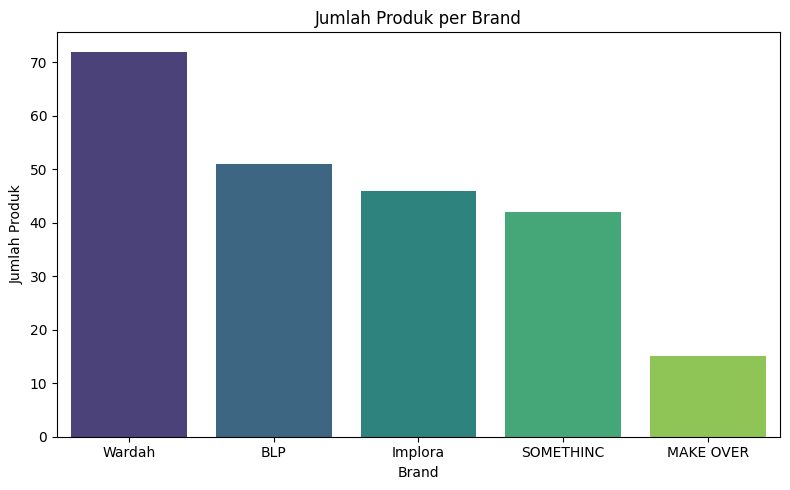

In [6]:
# Hitung frekuensi tiap brand
brand_counts = df['Brand'].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=brand_counts.index, y=brand_counts.values, palette='viridis')

plt.title('Jumlah Produk per Brand')
plt.xlabel('Brand')
plt.ylabel('Jumlah Produk')
plt.tight_layout()
plt.show()

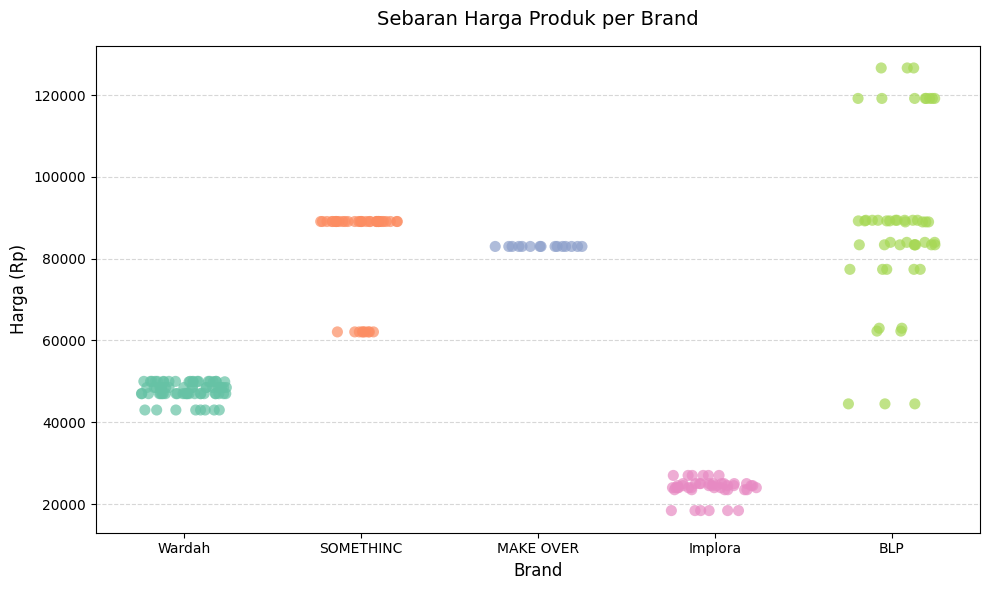

In [7]:
plt.figure(figsize=(10, 6))
sns.stripplot(
    data=df,
    x='Brand',
    y='Harga_Clean',
    hue='Brand',
    jitter=0.25,
    size=8,
    alpha=0.7,
    palette='Set2',
)

plt.title('Sebaran Harga Produk per Brand', fontsize=14, pad=15)
plt.xlabel('Brand', fontsize=12)
plt.ylabel('Harga (Rp)', fontsize=12)
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()